  BTC/USD - MLP ZA PREDVIDJANJE DNEVNE VOLATILNOSTI

 Ucitano 2834 dnevnih zapisa
  Period: 29.08.2017 -> 01.06.2025
 Feature engineering zavrsen

NaN pre ciscenja (max po koloni): 21
 Redova posle ciscenja: 2813

  Features: 13
  Ukupno uzoraka: 2813
  NaN u X: 0 | NaN u y: 0
  Redova posle mask filtera: 2813

  Trening: 2793 dana
    Od: 19.09.2017
    Do: 12.05.2025
  Test: 20 dana
    Od: 13.05.2025
    Do: 01.06.2025

  StandardScaler primenjen (mean=0, std=1)
  NaN u y_scaled: 0

  PCA: 13 features -> 7 komponenti (87.3% varijanse)
  Varijansa po komponenti:
    Komponenta 1: 25.0%
    Komponenta 2: 16.8%
    Komponenta 3: 11.8%
    Komponenta 4: 9.9%
    Komponenta 5: 8.6%
    Komponenta 6: 7.9%
    Komponenta 7: 7.2%

  Arhitektura:
  Ulazni sloj:     7 neurona (PCA)
  Skriveni sloj 1: 64 neurona (ReLU)
  Skriveni sloj 2: 32 neurona (ReLU)
  Skriveni sloj 3: 16 neurona (ReLU)
  Izlazni sloj:    1 neuron (volatilnost)
  Optimizer: Adam | LR: 0.0005 | L2 alpha: 0.001
  Batch size

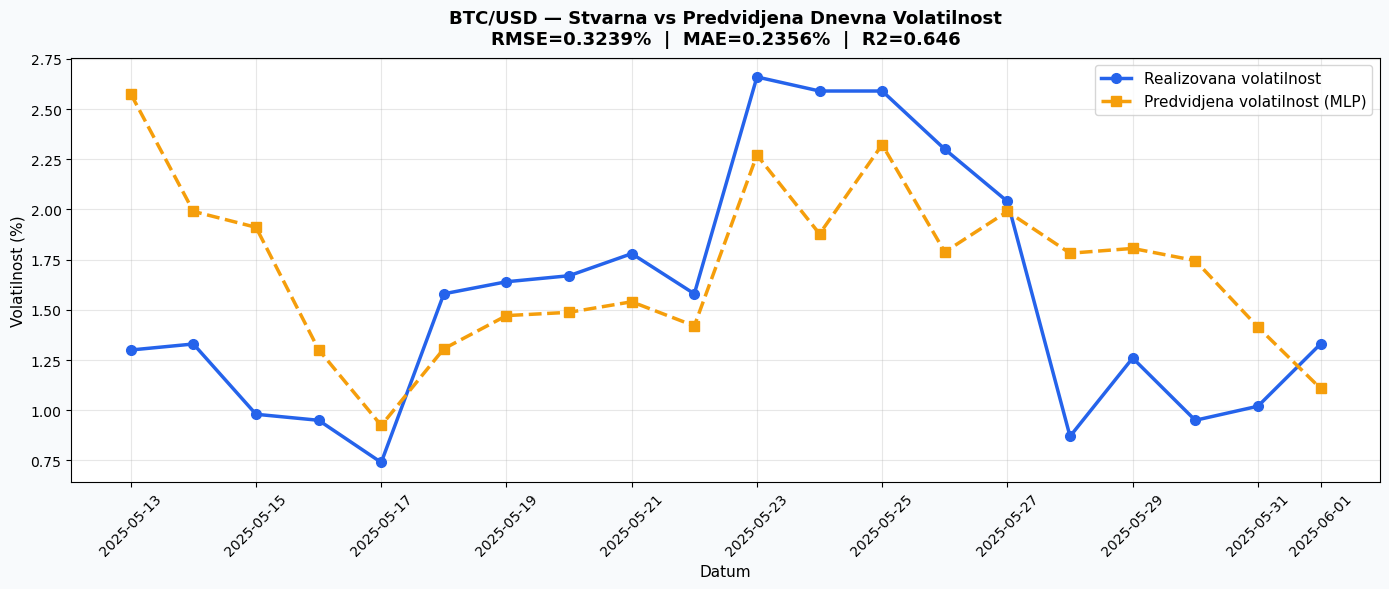


  SAZETAK REZULTATA - BTC/USD NEURONSKA MREZA

  PODACI:
  Instrument:      BTC/USD (dnevni podaci, Binance)
  Trening period:  Avg 2017 - Maj 2025 (2793 dana)
  Test period:     poslednjih 20 dana
                   (13.05.2025 -> 01.06.2025)

  ARHITEKTURA MLP:
  Ulazni sloj:     7 neurona (PCA od 13 feattura)
  Skriveni sloj 1: 64 neurona (ReLU)
  Skriveni sloj 2: 32 neurona (ReLU)
  Skriveni sloj 3: 16 neurona (ReLU)
  Izlazni sloj:    1 neuron (volatilnost)
  Optimizer:       Adam (LR=0.0005)
  Regularizacija:  L2 (alpha=0.001)
  Iteracije:       71

  PCA:
  Varijansa pokrivena: 87.3%

  CV REZULTATI (5 foldova):
  RMSE: 0.0055 +/- 0.0021
  MAE:  0.0037 +/- 0.0011
  R2:   0.873  +/- 0.048

  PERFORMANSE NA TEST SETU (20 dana):
  RMSE: 0.0032
  MAE:  0.0024
  R2:   0.646
  MAPE: 15.4%

  PREDVIDJANJE - OKTOBAR 2025:
  Dnevna volatilnost (annualizovana): 1.53%
  Interval pouzdanosti (+-1 RMSE):   [1.20%, 1.85%]

  Grafik sacuvan: btc_volatilnost_nn.png


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import warnings
warnings.filterwarnings('ignore')

from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# ─────────────────────────────────────────────────────────────
# BLOK 1: UCITAVANJE I CISCENJE
# ─────────────────────────────────────────────────────────────
print("=" * 60)
print("  BTC/USD - MLP ZA PREDVIDJANJE DNEVNE VOLATILNOSTI")
print("=" * 60)

df = pd.read_csv('/Users/tamaradrca/Podaci za diplomski/BTC_USD Binance Historical Data.csv')
df.columns = ['Date', 'Price', 'Open', 'High', 'Low', 'Volume', 'Change_pct']

# Parsiranje datuma
df['Date'] = pd.to_datetime(df['Date'], format='%m/%d/%Y')
df = df.sort_values('Date').reset_index(drop=True)

# Ciscenje numerickih kolona - BTC cena ima zareze npr. "4,587.5"
for col in ['Price', 'Open', 'High', 'Low']:
    df[col] = df[col].astype(str).str.replace(',', '').astype(float)

df['Change_pct'] = df['Change_pct'].astype(str).str.replace('%', '').astype(float)

# Volume ima K (hiljade), M (milione), B (milijarde) sufikse
def parse_volume(v):
    v = str(v).strip()
    if 'K' in v: return float(v.replace('K', '')) * 1e3
    if 'M' in v: return float(v.replace('M', '')) * 1e6
    if 'B' in v: return float(v.replace('B', '')) * 1e9
    try: return float(v)
    except: return np.nan

df['Volume'] = df['Volume'].apply(parse_volume)

print(f"\n Ucitano {len(df)} dnevnih zapisa")
print(f"  Period: {df['Date'].min().strftime('%d.%m.%Y')} -> {df['Date'].max().strftime('%d.%m.%Y')}")

# ─────────────────────────────────────────────────────────────
# BLOK 2: FEATURE ENGINEERING
# Dnevni podaci - koristimo krace prozore nego za nedeljne/mesecne
# ─────────────────────────────────────────────────────────────

# Dnevni log return
df['Log_Return'] = np.log(df['Price'] / df['Price'].shift(1))

# Rolling volatilnost - prozor 7 dana (nedeljni prozor za dnevne podatke)
# std dnevnih log returna poslednjih 7 dana
df['Volatility_7d'] = df['Log_Return'].rolling(7).std()

# High-Low raspon relativizovan cenom zatvaranja
# Za BTC ovo je posebno informativno jer su dnevni rasponi veliki
df['HL_Range'] = (df['High'] - df['Low']) / df['Price']

# Open-Close gap: smer pritiska tokom dana
df['OC_Gap'] = (df['Price'] - df['Open']) / df['Open']

# Procentualna promena obima trgovanja dan na dan
# Volume je vazan signal za kripto trziste
df['Vol_Change'] = df['Volume'].pct_change()

# Lagged log returni - 5 dana unazad (jedna radna nedelja)
df['Return_Lag1'] = df['Log_Return'].shift(1)
df['Return_Lag2'] = df['Log_Return'].shift(2)
df['Return_Lag3'] = df['Log_Return'].shift(3)
df['Return_Lag4'] = df['Log_Return'].shift(4)
df['Return_Lag5'] = df['Log_Return'].shift(5)

# Lagged volatilnost - prošla volatilnost predviđa buducu
df['Volat_Lag1'] = df['Volatility_7d'].shift(1)
df['Volat_Lag2'] = df['Volatility_7d'].shift(2)

# Moving averages - trend signali
df['MA7']  = df['Price'].rolling(7).mean()   # 7-dnevni prosek (1 nedelja)
df['MA21'] = df['Price'].rolling(21).mean()  # 21-dnevni prosek (~1 mesec)

# Koliko je trenutna cena iznad/ispod proseka
df['Price_vs_MA7']  = (df['Price'] - df['MA7'])  / df['MA7']
df['Price_vs_MA21'] = (df['Price'] - df['MA21']) / df['MA21']

# Momentum: promena u odnosu na N dana unazad
df['Momentum_7d']  = df['Price'] / df['Price'].shift(7)  - 1   # 1 nedelja
df['Momentum_21d'] = df['Price'] / df['Price'].shift(21) - 1   # ~1 mesec

print(f" Feature engineering zavrsen")

# ─────────────────────────────────────────────────────────────
# BLOK 3: TARGET VARIJABLA
# Dnevna realizovana volatilnost
# rolling(7).std() = std returna poslednjih 7 dana
# * sqrt(365) = annualizacija za kripto (radi 365 dana godisnje)
# ─────────────────────────────────────────────────────────────
df['Volatility_target'] = df['Log_Return'].rolling(7).std() 

# Uklanjamo NaN
print(f"\nNaN pre ciscenja (max po koloni): {df.isnull().sum().max()}")
df.dropna(inplace=True)
df.reset_index(drop=True, inplace=True)
print(f" Redova posle ciscenja: {len(df)}")

# ─────────────────────────────────────────────────────────────
# BLOK 4: FEATURES I TARGET
# ─────────────────────────────────────────────────────────────
FEATURES = [
    'Return_Lag1', 'Return_Lag2', 'Return_Lag3', 'Return_Lag4', 'Return_Lag5',
    'Volat_Lag1',  'Volat_Lag2',
    'HL_Range',    'OC_Gap',
    'Vol_Change',  'Change_pct',
    'Price_vs_MA7', 'Price_vs_MA21'
]

TARGET = 'Volatility_target'

X     = df[FEATURES].values
y     = df[TARGET].values
dates = df['Date'].values

print(f"\n  Features: {len(FEATURES)}")
print(f"  Ukupno uzoraka: {len(X)}")

stvarne_btc = [1.30, 1.33, 0.98, 0.95, 0.74, 1.58, 1.64, 1.67,
               1.78, 1.58, 2.66, 2.59, 2.59, 2.30, 2.04, 0.87,
               1.26, 0.95, 1.02, 1.33]

# ─────────────────────────────────────────────────────────────
# BLOK 5: CISCENJE NaN - MORA PRE SKALIRANJA
# ─────────────────────────────────────────────────────────────
mask  = ~(np.isnan(X).any(axis=1) | np.isnan(y) | np.isinf(X).any(axis=1) | np.isinf(y))
X     = X[mask]
y     = y[mask]
dates = dates[mask]

print(f"  NaN u X: {np.isnan(X).sum()} | NaN u y: {np.isnan(y).sum()}")
print(f"  Redova posle mask filtera: {len(y)}")

# ─────────────────────────────────────────────────────────────
# BLOK 6: PODELA TRENING / TEST
# Test: poslednjih 20 dana
# Trening: sve ostalo
# ─────────────────────────────────────────────────────────────
TEST_DAYS = 20
train_end = len(X) - TEST_DAYS

dates_pd = pd.to_datetime(dates)

print(f"\n  Trening: {train_end} dana")
print(f"    Od: {dates_pd[:train_end].min().strftime('%d.%m.%Y')}")
print(f"    Do: {dates_pd[:train_end].max().strftime('%d.%m.%Y')}")
print(f"  Test: {TEST_DAYS} dana")
print(f"    Od: {dates_pd[train_end:].min().strftime('%d.%m.%Y')}")
print(f"    Do: {dates_pd[train_end:].max().strftime('%d.%m.%Y')}")

# ─────────────────────────────────────────────────────────────
# BLOK 7: NORMALIZACIJA - fit SAMO na trening setu
# ─────────────────────────────────────────────────────────────
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_scaled  = scaler_X.fit_transform(X[:train_end])
X_full_sc = scaler_X.transform(X)
y_scaled  = scaler_y.fit_transform(y[:train_end].reshape(-1, 1)).ravel()

print(f"\n  StandardScaler primenjen (mean=0, std=1)")
print(f"  NaN u y_scaled: {np.isnan(y_scaled).sum()}")

# ─────────────────────────────────────────────────────────────
# BLOK 8: PCA - fiksno 7 komponenti
# ─────────────────────────────────────────────────────────────
pca = PCA(n_components=7, random_state=42)
X_train_pca = pca.fit_transform(X_scaled)
X_full_pca  = pca.transform(X_full_sc)

var_explained = pca.explained_variance_ratio_.cumsum()[-1]
print(f"\n  PCA: {len(FEATURES)} features -> 7 komponenti ({var_explained:.1%} varijanse)")
print(f"  Varijansa po komponenti:")
for i, v in enumerate(pca.explained_variance_ratio_):
    print(f"    Komponenta {i+1}: {v:.1%}")

# ─────────────────────────────────────────────────────────────
# BLOK 9: HIPERPARAMETRI
# ─────────────────────────────────────────────────────────────
HIDDEN_LAYERS = (64,32, 16)
ACTIVATION    = 'relu'
LEARNING_RATE = 0.0005
MAX_ITER      = 1000
ALPHA         = 0.001
BATCH_SIZE    = 64        # veci batch zbog velikog skupa (2800+ dana)

print(f"""
  Arhitektura:
  Ulazni sloj:     7 neurona (PCA)
  Skriveni sloj 1: {HIDDEN_LAYERS[0]} neurona (ReLU)
  Skriveni sloj 2: {HIDDEN_LAYERS[1]} neurona (ReLU)
  Skriveni sloj 3: {HIDDEN_LAYERS[2]} neurona (ReLU)
  Izlazni sloj:    1 neuron (volatilnost)
  Optimizer: Adam | LR: {LEARNING_RATE} | L2 alpha: {ALPHA}
  Batch size: {BATCH_SIZE} (prilagodjeno za {train_end} uzoraka)
""")

# ─────────────────────────────────────────────────────────────
# BLOK 10: WALK-FORWARD CROSS VALIDACIJA - 5 foldova
# Validacija SAMO na trening skupu
# ─────────────────────────────────────────────────────────────
print("-" * 55)
print("WALK-FORWARD CROSS VALIDACIJA (5 foldova)")
print("-" * 55)

tscv = TimeSeriesSplit(n_splits=5)
cv_rmse, cv_mae, cv_r2 = [], [], []

for fold, (tr_idx, val_idx) in enumerate(tscv.split(X_train_pca)):
    X_tr,  X_val = X_train_pca[tr_idx], X_train_pca[val_idx]
    y_tr,  y_val = y_scaled[tr_idx],    y_scaled[val_idx]

    model_cv = MLPRegressor(
        hidden_layer_sizes=HIDDEN_LAYERS,
        activation=ACTIVATION,
        solver='adam',
        alpha=ALPHA,
        learning_rate_init=LEARNING_RATE,
        max_iter=MAX_ITER,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=20,
        batch_size=BATCH_SIZE,
        random_state=42
    )
    model_cv.fit(X_tr, y_tr)

    pred_sc   = model_cv.predict(X_val)
    pred_real = scaler_y.inverse_transform(pred_sc.reshape(-1, 1)).ravel()
    y_real    = scaler_y.inverse_transform(y_val.reshape(-1, 1)).ravel()

    rmse = np.sqrt(mean_squared_error(y_real, pred_real))
    mae  = mean_absolute_error(y_real, pred_real)
    r2   = r2_score(y_real, pred_real)

    cv_rmse.append(rmse)
    cv_mae.append(mae)
    cv_r2.append(r2)
    print(f"  Fold {fold+1} ({len(val_idx)} dana): RMSE={rmse:.4f}  MAE={mae:.4f}  R2={r2:.3f}")

print(f"\n  Prosek -> RMSE={np.mean(cv_rmse):.4f} +/- {np.std(cv_rmse):.4f}")
print(f"           MAE ={np.mean(cv_mae):.4f} +/- {np.std(cv_mae):.4f}")
print(f"           R2  ={np.mean(cv_r2):.3f}  +/- {np.std(cv_r2):.3f}")

# ─────────────────────────────────────────────────────────────
# BLOK 11: FINALNI TRENING
# ─────────────────────────────────────────────────────────────
print("\n" + "-" * 55)
print("FINALNI TRENING")
print("-" * 55)

final_model = MLPRegressor(
    hidden_layer_sizes=HIDDEN_LAYERS,
    activation=ACTIVATION,
    solver='adam',
    alpha=ALPHA,
    learning_rate_init=LEARNING_RATE,
    max_iter=MAX_ITER,
    early_stopping=True,
    validation_fraction=0.15,
    n_iter_no_change=20,
    batch_size=BATCH_SIZE,
    random_state=42
)
final_model.fit(X_train_pca, y_scaled)

best_loss = final_model.best_loss_ if final_model.best_loss_ is not None else final_model.loss_curve_[-1]
print(f"  Trening zavrsen za {final_model.n_iter_} iteracija")
print(f"  Najbolji loss: {best_loss:.6f}")

# ─────────────────────────────────────────────────────────────
# BLOK 12: TESTIRANJE NA POSLEDNJIH 20 DANA
# ─────────────────────────────────────────────────────────────
print("\n" + "-" * 55)
print(f"TESTIRANJE (poslednjih {TEST_DAYS} dana)")
print("-" * 55)

X_test_pca     = X_full_pca[train_end:]
y_test         = y[train_end:]
test_dates     = dates[train_end:]

pred_test_sc   = final_model.predict(X_test_pca)
pred_test_real = scaler_y.inverse_transform(pred_test_sc.reshape(-1, 1)).ravel()

rmse_test = np.sqrt(mean_squared_error(y_test, pred_test_real))
mae_test  = mean_absolute_error(y_test, pred_test_real)
r2_test   = r2_score(y_test, pred_test_real)
mape_test = np.mean(np.abs((y_test - pred_test_real) / (np.abs(y_test) + 1e-8))) * 100

print(f"  RMSE: {rmse_test:.4f}")
print(f"  MAE:  {mae_test:.4f}")
print(f"  R2:   {r2_test:.3f}")
print(f"  MAPE: {mape_test:.1f}%")

pred_test_pct = pred_test_real * 100

test_df = pd.DataFrame({
    'Datum':                   pd.to_datetime(test_dates).strftime('%Y-%m-%d'),
    'Realizovana volatilnost': stvarne_btc,
    'Predvidjena volatilnost': pred_test_pct
})
print(f"\n  Predvidjanja za test period ({TEST_DAYS} dana):")
print(test_df.to_string(index=False))

# ─────────────────────────────────────────────────────────────
# BLOK 13: PREDVIDJANJE ZA OKTOBAR 2025
# Koristimo poslednje poznate vrednosti (Jun 2025)
# ─────────────────────────────────────────────────────────────
print("\n" + "-" * 55)
print("PREDVIDJANJE - OKTOBAR 2025")
print("-" * 55)

ret_d1 = np.log(df.iloc[-1]['Price'] / df.iloc[-2]['Price'])
ret_d2 = np.log(df.iloc[-2]['Price'] / df.iloc[-3]['Price'])
ret_d3 = np.log(df.iloc[-3]['Price'] / df.iloc[-4]['Price'])
ret_d4 = np.log(df.iloc[-4]['Price'] / df.iloc[-5]['Price'])
ret_d5 = np.log(df.iloc[-5]['Price'] / df.iloc[-6]['Price'])

vol_7d   = df['Log_Return'].iloc[-7:].std()
vol_prev = df['Log_Return'].iloc[-14:-7].std()

last = df.iloc[-1]

oct_features = np.array([[
    ret_d1, ret_d2, ret_d3, ret_d4, ret_d5,
    vol_7d, vol_prev,
    last['HL_Range'], last['OC_Gap'],
    last['Vol_Change'], last['Change_pct'],
    last['Price_vs_MA7'], last['Price_vs_MA21']
]])

oct_scaled  = scaler_X.transform(oct_features)
oct_pca     = pca.transform(oct_scaled)
oct_pred_sc = final_model.predict(oct_pca)
oct_vol     = scaler_y.inverse_transform(oct_pred_sc.reshape(-1, 1)).ravel()[0]

ci_low  = oct_vol - rmse_test
ci_high = oct_vol + rmse_test

print(f"\n  Predvidjena dnevna volatilnost Oktobar 2025: {oct_vol*100:.2f}%")
print(f"  (Annualizovana vrednost)")
print(f"  Interval pouzdanosti (+-1 RMSE): [{max(0,ci_low)*100:.2f}%, {ci_high*100:.2f}%]")

# ─────────────────────────────────────────────────────────────
# BLOK 14: VIZUALIZACIJA
# ─────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 6), facecolor='#F8FAFC')

test_d = pd.to_datetime(test_dates)

ax.plot(test_d, stvarne_btc,
        color='#2563EB', lw=2.5, marker='o', ms=7,
        label='Realizovana volatilnost')
ax.plot(test_d, pred_test_pct,
        color='#F59E0B', lw=2.5, marker='s', ms=7,
        linestyle='--', label='Predvidjena volatilnost (MLP)')

ax.set_title('BTC/USD — Stvarna vs Predvidjena Dnevna Volatilnost\n'
             f'RMSE={rmse_test*100:.4f}%  |  MAE={mae_test*100:.4f}%  |  R2={r2_test:.3f}',
             fontsize=13, fontweight='bold', pad=10)
ax.set_ylabel('Volatilnost (%)', fontsize=11)
ax.set_xlabel('Datum', fontsize=11)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
ax.set_facecolor('#FFFFFF')
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig('/Users/tamaradrca/Podaci za diplomski/btc_volatilnost_nn.png',
            dpi=150, bbox_inches='tight', facecolor='#F8FAFC')
plt.show()
plt.close()
# ─────────────────────────────────────────────────────────────
# BLOK 15: SAZETAK
# ─────────────────────────────────────────────────────────────
print("\n" + "=" * 60)
print("  SAZETAK REZULTATA - BTC/USD NEURONSKA MREZA")
print("=" * 60)
print(f"""
  PODACI:
  Instrument:      BTC/USD (dnevni podaci, Binance)
  Trening period:  Avg 2017 - Maj 2025 ({train_end} dana)
  Test period:     poslednjih {TEST_DAYS} dana
                   ({pd.to_datetime(test_dates[0]).strftime('%d.%m.%Y')} -> {pd.to_datetime(test_dates[-1]).strftime('%d.%m.%Y')})

  ARHITEKTURA MLP:
  Ulazni sloj:     7 neurona (PCA od {len(FEATURES)} feattura)
  Skriveni sloj 1: 64 neurona (ReLU)
  Skriveni sloj 2: 32 neurona (ReLU)
  Skriveni sloj 3: 16 neurona (ReLU)
  Izlazni sloj:    1 neuron (volatilnost)
  Optimizer:       Adam (LR={LEARNING_RATE})
  Regularizacija:  L2 (alpha={ALPHA})
  Iteracije:       {final_model.n_iter_}

  PCA:
  Varijansa pokrivena: {var_explained:.1%}

  CV REZULTATI (5 foldova):
  RMSE: {np.mean(cv_rmse):.4f} +/- {np.std(cv_rmse):.4f}
  MAE:  {np.mean(cv_mae):.4f} +/- {np.std(cv_mae):.4f}
  R2:   {np.mean(cv_r2):.3f}  +/- {np.std(cv_r2):.3f}

  PERFORMANSE NA TEST SETU ({TEST_DAYS} dana):
  RMSE: {rmse_test:.4f}
  MAE:  {mae_test:.4f}
  R2:   {r2_test:.3f}
  MAPE: {mape_test:.1f}%

  PREDVIDJANJE - OKTOBAR 2025:
  Dnevna volatilnost (annualizovana): {oct_vol*100:.2f}%
  Interval pouzdanosti (+-1 RMSE):   [{max(0,ci_low)*100:.2f}%, {ci_high*100:.2f}%]
""")
print("  Grafik sacuvan: btc_volatilnost_nn.png")
print("=" * 60)
